In [1]:
import sys
import random
from importlib.metadata import version

import numpy as np
import pandas as pd
from sklearn import set_config

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
set_config(display="text")

print("Python:", sys.version.split()[0])
for package in ["numpy", "pandas", "scikit-learn", "datasets"]:
    print(f"{package}: {version(package)}")
print("Random seed:", SEED)

Python: 3.13.16
numpy: 2.4.6
pandas: 2.2.3
scikit-learn: 1.6.1
datasets: 4.8.5
Random seed: 42


In [2]:
import io
import json
from zipfile import ZipFile
from google.colab import files

uploaded = files.upload()
assert len(uploaded) == 1, "Upload only m3_data_setup.zip."

archive_name, archive_bytes = next(iter(uploaded.items()))

with ZipFile(io.BytesIO(archive_bytes)) as archive:
    split_manifest = json.loads(archive.read("split_manifest.json"))
    saved_split_counts = pd.read_csv(
        io.BytesIO(archive.read("split_counts.csv"))
    )
    saved_split_overlap = pd.read_csv(
        io.BytesIO(archive.read("split_overlap.csv"))
    )

assert split_manifest["seed"] == SEED
assert split_manifest["dataset_revision"] == (
    "08978e21714984bb417547d2c0f9b477f5298163"
)

LABELS = split_manifest["labels"]
LABEL2ID = {label: index for index, label in enumerate(LABELS)}

print("Archive:", archive_name)
print("Dataset:", split_manifest["dataset"])
print("Revision:", split_manifest["dataset_revision"])
print("Label mapping:", LABEL2ID)
display(saved_split_counts)

Saving m3_data_setup.zip to m3_data_setup.zip
Archive: m3_data_setup.zip
Dataset: cnamuangtoun/resume-job-description-fit
Revision: 08978e21714984bb417547d2c0f9b477f5298163
Label mapping: {'Good Fit': 0, 'Potential Fit': 1, 'No Fit': 2}


,Split,Good Fit,Potential Fit,No Fit,Total,Unique jobs
0,Training,1258,1223,2600,5081,229
1,Validation,280,331,536,1147,51
2,Official test,458,444,857,1759,71


In [4]:
from datasets import load_dataset

DATASET_NAME = split_manifest["dataset"]
DATASET_REVISION = split_manifest["dataset_revision"]
REQUIRED_COLUMNS = ["resume_text", "job_description_text", "label"]

dataset = load_dataset(DATASET_NAME, revision=DATASET_REVISION)
split_frames = {}

for split_name, row_ids in split_manifest["source_row_ids"].items():
    source_name = split_manifest["source_splits"][split_name]
    source_data = dataset[source_name]

    assert len(row_ids) == len(set(row_ids))
    assert all(0 <= row_id < len(source_data) for row_id in row_ids)

    frame = source_data.select(row_ids).to_pandas()[REQUIRED_COLUMNS]
    frame["source_row_id"] = row_ids
    split_frames[split_name] = frame.reset_index(drop=True)

train_df = split_frames["Training"]
validation_df = split_frames["Validation"]
test_df = split_frames["Official test"]

actual_counts = pd.DataFrame({
    name: frame["label"].value_counts()
    for name, frame in split_frames.items()
}).reindex(LABELS).fillna(0).astype(int).T

actual_counts["Total"] = actual_counts.sum(axis=1)
expected_counts = saved_split_counts.set_index("Split")[
    LABELS + ["Total"]
]

pd.testing.assert_frame_equal(
    actual_counts, expected_counts, check_names=False
)

display(actual_counts)
print("All splits match the saved M3 row and class counts.")

label,Good Fit,Potential Fit,No Fit,Total
Training,1258,1223,2600,5081
Validation,280,331,536,1147
Official test,458,444,857,1759


All splits match the saved M3 row and class counts.


In [5]:
import re
import hashlib
import unicodedata

EMAIL_PATTERN = re.compile(
    r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b"
)
URL_PATTERN = re.compile(r"(?:https?://|www\.)\S+", re.IGNORECASE)
PHONE_PATTERN = re.compile(r"(?<!\w)(?:\+?\d[\d\s().-]{8,}\d)(?!\w)")


def prepare_text(text):
    text = unicodedata.normalize("NFKC", text)
    text = re.sub(r"\[([^\]]+)\]\([^)]+\)", r"\1", text)
    text = EMAIL_PATTERN.sub(" email ", text)
    text = URL_PATTERN.sub(" url ", text)
    text = PHONE_PATTERN.sub(
        lambda match: " phone "
        if sum(character.isdigit() for character in match.group()) >= 10
        else match.group(),
        text
    )
    text = text.replace("\r\n", "\n").replace("\r", "\n")
    text = re.sub(r"[^\S\n]+", " ", text)
    return re.sub(r"\n\s*\n+", "\n", text).strip()


def text_group_id(text):
    normalized = " ".join(text.casefold().split())
    return hashlib.sha256(normalized.encode("utf-8")).hexdigest()


assert prepare_text("Skills: C++, C#, .NET") == "Skills: C++, C#, .NET"
print("M3 text-preparation functions are ready.")

M3 text-preparation functions are ready.


In [6]:
def prepare_frame(frame):
    result = frame.copy()
    result["resume_model_text"] = result["resume_text"].map(prepare_text)
    result["job_model_text"] = result["job_description_text"].map(prepare_text)
    result["resume_group"] = result["resume_model_text"].map(text_group_id)
    result["job_group"] = result["job_model_text"].map(text_group_id)
    result["labels"] = result["label"].map(LABEL2ID)

    assert result["labels"].notna().all()
    result["labels"] = result["labels"].astype("int64")
    return result


split_frames = {
    name: prepare_frame(frame)
    for name, frame in split_frames.items()
}

train_df = split_frames["Training"]
validation_df = split_frames["Validation"]
test_df = split_frames["Official test"]

MODEL_PAIR_COLUMNS = ["resume_group", "job_group"]
preparation_rows = []

for name, frame in split_frames.items():
    preparation_rows.append({
        "Split": name,
        "Rows": len(frame),
        "Unique jobs": frame["job_group"].nunique(),
        "Empty resumes": int(frame["resume_model_text"].eq("").sum()),
        "Empty jobs": int(frame["job_model_text"].eq("").sum()),
        "Duplicate pairs": int(frame.duplicated(MODEL_PAIR_COLUMNS).sum())
    })
    assert set(frame["labels"]) == set(LABEL2ID.values())

preparation_report = pd.DataFrame(preparation_rows)

assert preparation_report[
    ["Empty resumes", "Empty jobs", "Duplicate pairs"]
].to_numpy().sum() == 0

pd.testing.assert_series_equal(
    preparation_report.set_index("Split")["Unique jobs"],
    saved_split_counts.set_index("Split")["Unique jobs"]
)

display(preparation_report)
print("Text preparation and within-split checks passed.")

,Split,Rows,Unique jobs,Empty resumes,Empty jobs,Duplicate pairs
0,Training,5081,229,0,0,0
1,Validation,1147,51,0,0,0
2,Official test,1759,71,0,0,0


Text preparation and within-split checks passed.


In [7]:
from itertools import combinations

overlap_rows = []

for (first_name, first_df), (second_name, second_df) in combinations(
    split_frames.items(), 2
):
    first_pairs = set(
        first_df[MODEL_PAIR_COLUMNS].itertuples(index=False, name=None)
    )
    second_pairs = set(
        second_df[MODEL_PAIR_COLUMNS].itertuples(index=False, name=None)
    )

    overlap_rows.append({
        "Comparison": f"{first_name} / {second_name}",
        "Shared jobs": len(
            set(first_df["job_group"]) & set(second_df["job_group"])
        ),
        "Shared resumes": len(
            set(first_df["resume_group"]) & set(second_df["resume_group"])
        ),
        "Shared pairs": len(first_pairs & second_pairs)
    })

split_overlap_report = pd.DataFrame(overlap_rows)

pd.testing.assert_frame_equal(split_overlap_report, saved_split_overlap)
assert split_overlap_report["Shared jobs"].eq(0).all()
assert split_overlap_report["Shared pairs"].eq(0).all()

display(split_overlap_report)
print("Overlap matches M3 exactly. No jobs or pairs are shared across splits.")

,Comparison,Shared jobs,Shared resumes,Shared pairs
0,Training / Validation,0,429,0
1,Training / Official test,0,473,0
2,Validation / Official test,0,357,0


Overlap matches M3 exactly. No jobs or pairs are shared across splits.


In [8]:
BASELINE_LINK_PATTERN = re.compile(r"\[([^\]]+)\]\([^)]+\)")
BASELINE_EMAIL_PATTERN = re.compile(
    r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b"
)
BASELINE_URL_PATTERN = re.compile(r"(?:https?://|www\.)\S+")
BASELINE_PHONE_PATTERN = re.compile(
    r"(?<!\w)(?:\+?\d[\d\s().-]{8,}\d)(?!\w)"
)
BASELINE_UNWANTED_PATTERN = re.compile(r"[^a-z0-9+#.\s]")


def baseline_clean_text(text):
    if pd.isna(text):
        return ""

    text = str(text).lower()
    text = BASELINE_LINK_PATTERN.sub(r"\1", text)
    text = BASELINE_EMAIL_PATTERN.sub(" email ", text)
    text = BASELINE_URL_PATTERN.sub(" url ", text)
    text = BASELINE_PHONE_PATTERN.sub(
        lambda match: " phone "
        if sum(character.isdigit() for character in match.group()) >= 10
        else match.group(),
        text
    )
    text = BASELINE_UNWANTED_PATTERN.sub(" ", text)
    return re.sub(r"\s+", " ", text).strip()


assert baseline_clean_text("Skills: C++, C#, .NET") == "skills c++ c# .net"
assert baseline_clean_text("Contact: user@example.com") == "contact email"

print("Original TF-IDF cleaning function is ready.")

Original TF-IDF cleaning function is ready.


In [9]:
def create_baseline_pairs(frame):
    resumes = frame["resume_text"].map(baseline_clean_text)
    jobs = frame["job_description_text"].map(baseline_clean_text)

    assert resumes.str.strip().ne("").all()
    assert jobs.str.strip().ne("").all()

    return "resume " + resumes + " job " + jobs


train_pair_text = create_baseline_pairs(train_df)
validation_pair_text = create_baseline_pairs(validation_df)

pair_text_report = pd.DataFrame([
    {
        "Split": name,
        "Pairs": len(texts),
        "Mean words per pair": round(
            texts.str.split().str.len().mean(), 1
        ),
        "Empty pairs": int(texts.str.strip().eq("").sum())
    }
    for name, texts in [
        ("Training", train_pair_text),
        ("Validation", validation_pair_text)
    ]
])

assert len(train_pair_text) == 5081
assert len(validation_pair_text) == 1147
assert train_pair_text.index.equals(train_df.index)
assert validation_pair_text.index.equals(validation_df.index)

display(pair_text_report)
print("Training and validation pairs are ready.")

,Split,Pairs,Mean words per pair,Empty pairs
0,Training,5081,1148.7,0
1,Validation,1147,1063.8,0


Training and validation pairs are ready.


In [10]:
import time
from sklearn.feature_extraction.text import TfidfVectorizer

paired_vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=50000,
    min_df=3,
    max_df=0.98,
    sublinear_tf=True,
    stop_words="english"
)

vectorization_started = time.perf_counter()

train_pair_matrix = paired_vectorizer.fit_transform(train_pair_text)
validation_pair_matrix = paired_vectorizer.transform(validation_pair_text)

vectorization_seconds = time.perf_counter() - vectorization_started

assert train_pair_matrix.shape[0] == len(train_df)
assert validation_pair_matrix.shape[0] == len(validation_df)
assert train_pair_matrix.shape[1] == validation_pair_matrix.shape[1]
assert np.isfinite(train_pair_matrix.data).all()
assert np.isfinite(validation_pair_matrix.data).all()

density = (
    train_pair_matrix.nnz
    / (train_pair_matrix.shape[0] * train_pair_matrix.shape[1])
    * 100
)

print("Vocabulary size:", len(paired_vectorizer.vocabulary_))
print("Training matrix:", train_pair_matrix.shape)
print("Validation matrix:", validation_pair_matrix.shape)
print(f"Training matrix density: {density:.4f}%")
print(f"Vectorization time: {vectorization_seconds:.2f} seconds")
print("TF-IDF fitted on training rows only.")

Vocabulary size: 50000
Training matrix: (5081, 50000)
Validation matrix: (1147, 50000)
Training matrix density: 1.7834%
Vectorization time: 16.63 seconds
TF-IDF fitted on training rows only.


In [11]:
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import accuracy_score, f1_score, recall_score

sgd_classifier = SGDClassifier(
    loss="log_loss",
    alpha=1e-5,
    random_state=SEED
)

training_started = time.perf_counter()
sgd_classifier.fit(train_pair_matrix, train_df["label"])
training_seconds = time.perf_counter() - training_started

validation_predictions = sgd_classifier.predict(validation_pair_matrix)

validation_recalls = recall_score(
    validation_df["label"],
    validation_predictions,
    labels=LABELS,
    average=None,
    zero_division=0
)

validation_metrics = {
    "accuracy": accuracy_score(
        validation_df["label"], validation_predictions
    ),
    "macro_f1": f1_score(
        validation_df["label"], validation_predictions,
        labels=LABELS, average="macro", zero_division=0
    ),
    "weighted_f1": f1_score(
        validation_df["label"], validation_predictions,
        labels=LABELS, average="weighted", zero_division=0
    ),
    "recall_good_fit": validation_recalls[0],
    "recall_potential_fit": validation_recalls[1],
    "recall_no_fit": validation_recalls[2]
}

assert set(sgd_classifier.classes_) == set(LABELS)

display(pd.DataFrame([validation_metrics], index=["Validation"]).round(4))
print("Training iterations:", sgd_classifier.n_iter_)
print(f"Classifier training time: {training_seconds:.2f} seconds")
print("Official test set has not been evaluated.")

,accuracy,macro_f1,weighted_f1,recall_good_fit,recall_potential_fit,recall_no_fit
Validation,0.4429,0.2923,0.36,0.0143,0.1964,0.819


Training iterations: 48
Classifier training time: 6.66 seconds
Official test set has not been evaluated.


In [12]:
from sklearn.metrics import classification_report, confusion_matrix

validation_class_report = pd.DataFrame(
    classification_report(
        validation_df["label"],
        validation_predictions,
        labels=LABELS,
        output_dict=True,
        zero_division=0
    )
).T.loc[LABELS]

validation_confusion_matrix = pd.DataFrame(
    confusion_matrix(
        validation_df["label"],
        validation_predictions,
        labels=LABELS
    ),
    index=pd.Index(LABELS, name="True label"),
    columns=pd.Index(LABELS, name="Predicted label")
)

validation_prediction_counts = (
    pd.Series(validation_predictions)
    .value_counts()
    .reindex(LABELS, fill_value=0)
    .rename("Predicted count")
)

assert validation_confusion_matrix.to_numpy().sum() == len(validation_df)
assert validation_confusion_matrix.sum(axis=1).tolist() == [280, 331, 536]
assert (
    validation_confusion_matrix.sum(axis=0).tolist()
    == validation_prediction_counts.tolist()
)

display(validation_class_report.round(4))
display(validation_confusion_matrix)
display(validation_prediction_counts.to_frame())

,precision,recall,f1-score,support
Good Fit,0.1143,0.0143,0.0254,280.0
Potential Fit,0.3316,0.1964,0.2467,331.0
No Fit,0.4793,0.8190,0.6047,536.0


Predicted label,Good Fit,Potential Fit,No Fit
True label,,,
Good Fit,4,57,219
Potential Fit,8,65,258
No Fit,23,74,439


,Predicted count
Good Fit,35
Potential Fit,196
No Fit,916


In [13]:
from pathlib import Path

RUN_DIR = Path("/content/m4_reference/tfidf_sgd_v1")
REPORT_DIR = RUN_DIR / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

validation_prediction_report = pd.DataFrame({
    "source_row_id": validation_df["source_row_id"].to_numpy(),
    "true_label": validation_df["label"].to_numpy(),
    "predicted_label": validation_predictions
})
validation_prediction_report["correct"] = (
    validation_prediction_report["true_label"]
    == validation_prediction_report["predicted_label"]
)

validation_class_report.to_csv(
    REPORT_DIR / "validation_class_report.csv",
    index_label="label"
)
validation_confusion_matrix.to_csv(
    REPORT_DIR / "validation_confusion_matrix.csv"
)
validation_prediction_report.to_csv(
    REPORT_DIR / "validation_predictions.csv", index=False
)
(REPORT_DIR / "validation_metrics.json").write_text(
    json.dumps(validation_metrics, indent=2),
    encoding="utf-8"
)

preparation_report.to_csv(
    REPORT_DIR / "preparation_report.csv", index=False
)
split_overlap_report.to_csv(
    REPORT_DIR / "split_overlap.csv", index=False
)

assert len(validation_prediction_report) == 1147
assert int(validation_prediction_report["correct"].sum()) == 508

print("Reports saved to:", REPORT_DIR)
for path in sorted(REPORT_DIR.iterdir()):
    print(f"{path.name}: {path.stat().st_size:,} bytes")

Reports saved to: /content/m4_reference/tfidf_sgd_v1/reports
preparation_report.csv: 141 bytes
split_overlap.csv: 149 bytes
validation_class_report.csv: 268 bytes
validation_confusion_matrix.csv: 99 bytes
validation_metrics.json: 238 bytes
validation_predictions.csv: 32,339 bytes


In [14]:
vectorizer_settings = paired_vectorizer.get_params(deep=False).copy()
vectorizer_settings["dtype"] = np.dtype(
    vectorizer_settings["dtype"]
).name

reference_config = {
    "run_id": "tfidf_sgd_v1",
    "dataset": DATASET_NAME,
    "dataset_revision": DATASET_REVISION,
    "seed": SEED,
    "split_manifest_sha256": hashlib.sha256(
        json.dumps(
            split_manifest, sort_keys=True, separators=(",", ":")
        ).encode("utf-8")
    ).hexdigest(),
    "split_rows": {
        name: len(frame) for name, frame in split_frames.items()
    },
    "labels": LABELS,
    "preprocessing": "Original M2 baseline cleaning applied to raw text",
    "pair_format": "resume {cleaned_resume} job {cleaned_job}",
    "input_truncation": None,
    "vectorizer": vectorizer_settings,
    "classifier": sgd_classifier.get_params(deep=False),
    "python_version": sys.version.split()[0],
    "package_versions": {
        package: version(package)
        for package in ["numpy", "pandas", "scikit-learn", "datasets"]
    }
}

run_summary = {
    "run_id": "tfidf_sgd_v1",
    "validation_metrics": validation_metrics,
    "validation_prediction_counts": {
        label: int(count)
        for label, count in validation_prediction_counts.items()
    },
    "vocabulary_size": len(paired_vectorizer.vocabulary_),
    "classifier_iterations": int(sgd_classifier.n_iter_),
    "vectorization_seconds": vectorization_seconds,
    "classifier_training_seconds": training_seconds,
    "official_test_evaluated": False
}

for filename, content in [
    ("reference_config.json", reference_config),
    ("run_summary.json", run_summary)
]:
    (REPORT_DIR / filename).write_text(
        json.dumps(content, indent=2), encoding="utf-8"
    )

print("Configuration and run summary saved.")
print("Validation macro-F1:", round(validation_metrics["macro_f1"], 4))
print("Official test evaluated:", run_summary["official_test_evaluated"])

Configuration and run summary saved.
Validation macro-F1: 0.2923
Official test evaluated: False


In [15]:
import joblib
from sklearn.pipeline import Pipeline

MODEL_DIR = RUN_DIR / "model"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

reference_pipeline = Pipeline([
    ("tfidf", paired_vectorizer),
    ("classifier", sgd_classifier)
])

model_path = MODEL_DIR / "tfidf_sgd_pipeline.joblib"
joblib.dump(reference_pipeline, model_path, compress=3)

reloaded_pipeline = joblib.load(model_path)
reloaded_predictions = reloaded_pipeline.predict(validation_pair_text)

np.testing.assert_array_equal(
    reloaded_predictions, validation_predictions
)
assert reloaded_pipeline.named_steps["tfidf"].vocabulary_ == (
    paired_vectorizer.vocabulary_
)
np.testing.assert_array_equal(
    reloaded_pipeline.named_steps["classifier"].coef_,
    sgd_classifier.coef_
)
np.testing.assert_array_equal(
    reloaded_pipeline.named_steps["classifier"].intercept_,
    sgd_classifier.intercept_
)

reload_check = {
    "vocabulary_matches": True,
    "classifier_weights_match_exactly": True,
    "validation_predictions_match_exactly": True,
    "validation_examples_checked": len(validation_pair_text),
    "model_input": "Cleaned pair text using the recorded baseline preparation",
    "passed": True
}
(REPORT_DIR / "reload_check.json").write_text(
    json.dumps(reload_check, indent=2), encoding="utf-8"
)

print(f"Saved model: {model_path}")
print(f"Model size: {model_path.stat().st_size / 1024**2:.2f} MB")
print("Reload checks passed for all 1,147 validation predictions.")

Saved model: /content/m4_reference/tfidf_sgd_v1/model/tfidf_sgd_pipeline.joblib
Model size: 1.35 MB
Reload checks passed for all 1,147 validation predictions.


In [16]:
uploaded_reports = files.upload()
assert len(uploaded_reports) == 2, "Upload the two M3 reports ZIP files."

transformer_runs = {}

for archive_name, archive_bytes in uploaded_reports.items():
    with ZipFile(io.BytesIO(archive_bytes)) as archive:
        summary = json.loads(archive.read("run_summary.json"))
        metrics = json.loads(archive.read("validation_metrics.json"))
        config = json.loads(archive.read("tokenization_config.json"))

    run_id = summary["run_id"]
    assert run_id in {"minilm_v1", "distilbert_v1"}
    assert run_id not in transformer_runs
    assert summary["dataset_revision"] == DATASET_REVISION
    assert summary["seed"] == SEED
    assert summary["split_rows"] == reference_config["split_rows"]
    assert summary["official_test_evaluated"] is False
    assert config["label2id"] == LABEL2ID

    transformer_runs[run_id] = {
        "summary": summary,
        "metrics": metrics,
        "tokenization_config": config
    }
    print(f"Loaded: {archive_name} ({run_id})")

assert set(transformer_runs) == {"minilm_v1", "distilbert_v1"}
assert (
    transformer_runs["minilm_v1"]["tokenization_config"]
    == transformer_runs["distilbert_v1"]["tokenization_config"]
)

print("Both M3 reports loaded. Revision, seed, split counts, and labels match.")

Saving distilbert_v1_reports.zip to distilbert_v1_reports.zip
Saving minilm_v1_reports.zip to minilm_v1_reports.zip
Loaded: distilbert_v1_reports.zip (distilbert_v1)
Loaded: minilm_v1_reports.zip (minilm_v1)
Both M3 reports loaded. Revision, seed, split counts, and labels match.


In [17]:
comparison_rows = [{
    "Model": "TF-IDF + SGD",
    "Validation macro-F1": validation_metrics["macro_f1"],
    "Validation accuracy": validation_metrics["accuracy"],
    "Good Fit recall": validation_metrics["recall_good_fit"],
    "Potential Fit recall": validation_metrics["recall_potential_fit"],
    "No Fit recall": validation_metrics["recall_no_fit"]
}]

for run_id, model_name in [
    ("minilm_v1", "MiniLM"),
    ("distilbert_v1", "DistilBERT")
]:
    metrics = transformer_runs[run_id]["metrics"]

    comparison_rows.append({
        "Model": model_name,
        "Validation macro-F1": metrics["validation_macro_f1"],
        "Validation accuracy": metrics["validation_accuracy"],
        "Good Fit recall": metrics["validation_recall_good_fit"],
        "Potential Fit recall": metrics["validation_recall_potential_fit"],
        "No Fit recall": metrics["validation_recall_no_fit"]
    })

comparison_df = pd.DataFrame(comparison_rows)

COMPARISON_DIR = RUN_DIR / "comparison"
COMPARISON_DIR.mkdir(parents=True, exist_ok=True)
comparison_df.to_csv(
    COMPARISON_DIR / "reference_model_comparison.csv", index=False
)

reference_f1 = validation_metrics["macro_f1"]

display(comparison_df.round(4))
for row in comparison_rows[1:]:
    gain = row["Validation macro-F1"] - reference_f1
    print(f"{row['Model']} macro-F1 gain over reference: {gain:+.4f}")

print("Comparison saved. All scores use validation data.")

,Model,Validation macro-F1,Validation accuracy,Good Fit recall,Potential Fit recall,No Fit recall
0,TF-IDF + SGD,0.2923,0.4429,0.0143,0.1964,0.8190
1,MiniLM,0.3081,0.4682,0.2643,0.0000,0.8638
2,DistilBERT,0.3540,0.4752,0.2107,0.1088,0.8396


MiniLM macro-F1 gain over reference: +0.0159
DistilBERT macro-F1 gain over reference: +0.0618
Comparison saved. All scores use validation data.


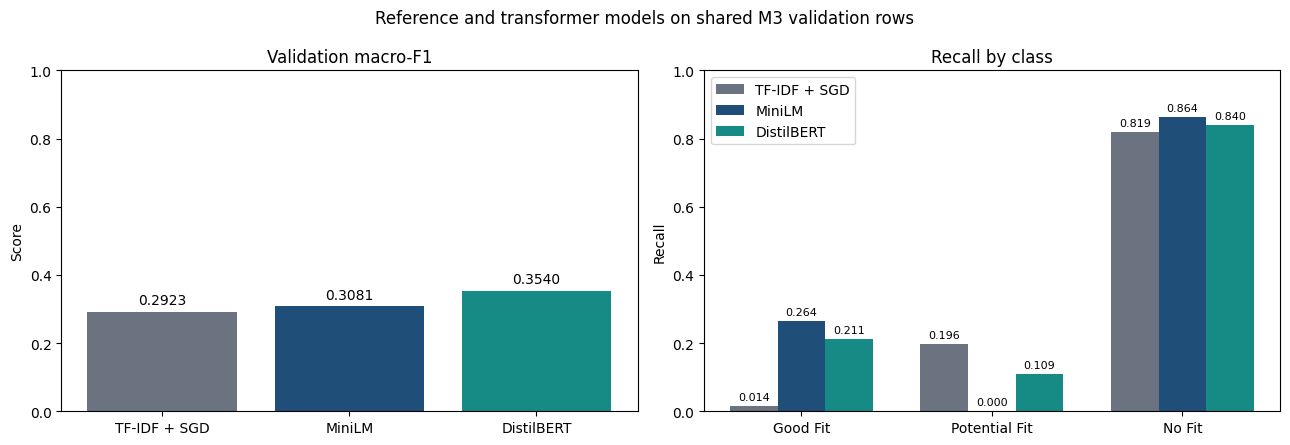

Figure saved to: /content/m4_reference/tfidf_sgd_v1/comparison/reference_model_comparison.png


In [18]:
import matplotlib.pyplot as plt

colors = ["#6B7280", "#1F4E79", "#168A84"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

bars = axes[0].bar(
    comparison_df["Model"],
    comparison_df["Validation macro-F1"],
    color=colors
)
axes[0].bar_label(bars, fmt="%.4f", padding=3)
axes[0].set_title("Validation macro-F1")
axes[0].set_ylabel("Score")
axes[0].set_ylim(0, 1)

positions = np.arange(len(LABELS))
width = 0.25
recall_columns = ["Good Fit recall", "Potential Fit recall", "No Fit recall"]

for index, row in comparison_df.iterrows():
    bars = axes[1].bar(
        positions + (index - 1) * width,
        row[recall_columns].to_numpy(dtype=float),
        width=width,
        label=row["Model"],
        color=colors[index]
    )
    axes[1].bar_label(bars, fmt="%.3f", padding=3, fontsize=8)

axes[1].set_xticks(positions, LABELS)
axes[1].set_title("Recall by class")
axes[1].set_ylabel("Recall")
axes[1].set_ylim(0, 1)
axes[1].legend()

fig.suptitle("Reference and transformer models on shared M3 validation rows")
fig.tight_layout()

figure_path = COMPARISON_DIR / "reference_model_comparison.png"
fig.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Figure saved to:", figure_path)

In [19]:
scores = comparison_df.set_index("Model")

comparison_notes = f"""# Reference Model Evaluation

## Evaluation setup

The TF-IDF reference and both transformers use the same M3 source rows,
dataset revision, labels, and job-grouped validation split.
No jobs or prepared resume-job pairs overlap between splits.
Some resumes are shared, so this evaluates matching a largely known
candidate pool against unseen jobs.

TF-IDF retains its original baseline cleaning and uses full documents.
The transformers use their recorded preparation and 512-token truncation.
This compares complete approaches; it does not isolate architecture alone.

TF-IDF vocabulary and classifier fitting use training rows only.
The original baseline settings are retained without a validation search.

## Findings

- TF-IDF + SGD validation macro-F1: {scores.loc["TF-IDF + SGD", "Validation macro-F1"]:.4f}.
- MiniLM validation macro-F1: {scores.loc["MiniLM", "Validation macro-F1"]:.4f}.
- DistilBERT validation macro-F1: {scores.loc["DistilBERT", "Validation macro-F1"]:.4f}.
- DistilBERT's absolute gain over the reference: {scores.loc["DistilBERT", "Validation macro-F1"] - reference_f1:.4f}.
- TF-IDF identifies 4 of 280 Good Fit examples and 65 of 331 Potential Fit examples.
- TF-IDF has the highest Potential Fit recall among these runs.
- MiniLM has the highest Good Fit recall.
- DistilBERT leads on macro-F1 and accuracy.

## Limitations and next steps

These are single-seed validation results, not final test results.
All approaches miss many suitable candidates.
Historical M2 test scores use a different split and are not directly comparable.

The saved TF-IDF pipeline reproduces all 1,147 validation predictions.
It expects cleaned pair text, not raw resume and job fields.

Keep this run as the fixed reference for class-weighted training and
section-aware input experiments. Select settings using validation data.
Evaluate the official test set after model selection is fixed.
"""

notes_path = COMPARISON_DIR / "comparison_notes.md"
notes_path.write_text(comparison_notes, encoding="utf-8")

print("Comparison findings saved to:", notes_path)

Comparison findings saved to: /content/m4_reference/tfidf_sgd_v1/comparison/comparison_notes.md


In [20]:
saved_predictions = pd.read_csv(
    REPORT_DIR / "validation_predictions.csv"
)
saved_metrics = json.loads(
    (REPORT_DIR / "validation_metrics.json").read_text()
)
saved_confusion = pd.read_csv(
    REPORT_DIR / "validation_confusion_matrix.csv", index_col=0
)

np.testing.assert_array_equal(
    saved_predictions["source_row_id"],
    validation_df["source_row_id"]
)
np.testing.assert_array_equal(
    saved_predictions["true_label"],
    validation_df["label"]
)
np.testing.assert_array_equal(
    saved_predictions["predicted_label"],
    validation_predictions
)

recomputed_f1 = f1_score(
    saved_predictions["true_label"],
    saved_predictions["predicted_label"],
    labels=LABELS,
    average="macro",
    zero_division=0
)
np.testing.assert_allclose(
    recomputed_f1, saved_metrics["macro_f1"], rtol=1e-12
)
np.testing.assert_array_equal(
    confusion_matrix(
        saved_predictions["true_label"],
        saved_predictions["predicted_label"],
        labels=LABELS
    ),
    saved_confusion.to_numpy()
)
pd.testing.assert_frame_equal(
    pd.read_csv(COMPARISON_DIR / "reference_model_comparison.csv"),
    comparison_df,
    check_exact=False,
    rtol=1e-12,
    atol=1e-12
)

assert run_summary["official_test_evaluated"] is False
assert json.loads((REPORT_DIR / "reload_check.json").read_text())["passed"]

print("Saved predictions, source rows, metrics, and confusion matrix match.")
print("Comparison CSV and model reload checks passed.")
print("Official test set remains unevaluated.")

Saved predictions, source rows, metrics, and confusion matrix match.
Comparison CSV and model reload checks passed.
Official test set remains unevaluated.


In [21]:
from zipfile import ZIP_DEFLATED

reports_archive = Path("/content/tfidf_sgd_v1_reports.zip")
model_archive = Path("/content/tfidf_sgd_v1_model.zip")

with ZipFile(reports_archive, "w", ZIP_DEFLATED) as archive:
    for path in sorted(REPORT_DIR.iterdir()):
        if path.is_file():
            archive.write(path, path.name)

    for path in sorted(COMPARISON_DIR.iterdir()):
        if path.is_file():
            archive.write(path, f"comparison/{path.name}")

with ZipFile(model_archive, "w", ZIP_DEFLATED) as archive:
    archive.write(model_path, model_path.name)
    archive.write(
        REPORT_DIR / "reference_config.json",
        "reference_config.json"
    )

for path in [reports_archive, model_archive]:
    with ZipFile(path) as archive:
        assert archive.testzip() is None
        print(
            f"{path.name}: {len(archive.namelist())} files, "
            f"{path.stat().st_size / 1024**2:.2f} MB"
        )

files.download(str(reports_archive))
files.download(str(model_archive))

tfidf_sgd_v1_reports.zip: 12 files, 0.12 MB
tfidf_sgd_v1_model.zip: 2 files, 1.35 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>